# Simulazione MC di frange di intensità luminosità
## Fase Preliminare
In questa fase preliminare abbiamo settato le informazioni di base del programma:

In [45]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

B = 20  # fondo uniforme
I0 = 400  # scala del segnale
alpha = 0.90  # larghezza dell'inviluppo
delta = 5.20  # fraequenza spaziale delle frange

x = np.linspace(-5.0, 5.0, 161) # 161 punti equidistanti tra -5.0 mm e 5.0 mm

## Attività 1
Lo scopo di questa prima attività è costruire il modello fisico per la descrizione dell'esperimento e rappresentare graficamente la distribuzione teorica, il fondo e l'inviluppo superiore.

Il modello che seguiremo è il seguente: 
$$ \mu(x) = B + I_0 (\frac{\sin(\alpha  x)}{\alpha  x})^2  \cos(\delta  x)^2 $$
dove i parametri sono stati settati nella fase preliminare.

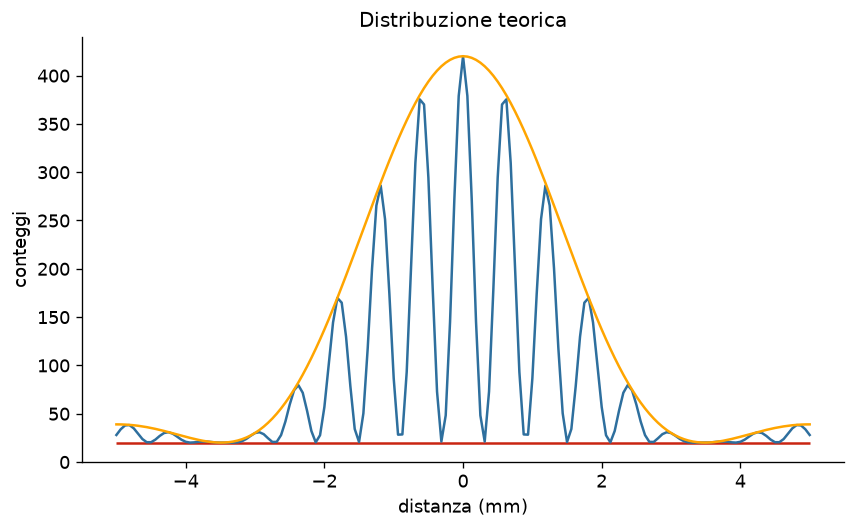

In [46]:
def E(x):
    return np.sinc(alpha * x / np.pi) ** 2


def C(x):
    return np.cos(delta * x) ** 2

def mu(x):
    mu_values = B + I0 * E(x) * C(x)

    np.all(np.isfinite(mu_values))  # valori finiti
    np.all(mu_values >= 0)  # valori positivi
    np.allclose(mu_values, mu_values[::-1])  # valori simmetrici

    return mu_values


fig, ax = plt.subplots()
ax.set(xlabel="distanza (mm)", ylabel="conteggi", title="Distribuzione teorica")
ax.hlines(B, -5, 5, color=ROSSO)
ax.plot(x, mu(x), color=AZZURRO)
ax.plot(x, B + I0 * E(x), color=ARANCIONE)
plt.show()

Nota: la funzione non presenta una discontinuità in $x = 0$ perchè il valore in quel punto viene calcolato dalla funzione `np.sinc` tramite il limite notevole: 
$$ \lim_{x \to 0}  \frac{sin(x)}{x} = 1 $$

## Attività 2
Dopo aver studiato la distribuzione teorica dei conteggi, passiamo alla simulazione di una acquisizione dati in laboratorio. 
Per fare ciò utilizziamo la distribuzione di Poisson per stimare il valore di conteggi ad una determinata x:
$$ n_i \sim Poisson(\mu(x_i)) $$
dove ogni conteggio viene assegnato un errore di $\sqrt(n_i)$ (nel caso il risultato di un conteggio sia nullo viene attribuito di default un errore pari a 1).

In seguito vengono calcolati il numero di conteggi simulati e il numero di conteggi stimati dalla distribuzione teorica nella regione centrale.
$$ N_c = \sum_{\lvert(x_i)\rvert < 1.2 mm} n_i$$
$$ \mu_c = \sum_{\lvert(x_i)\rvert < 1.2 mm} \mu_i$$

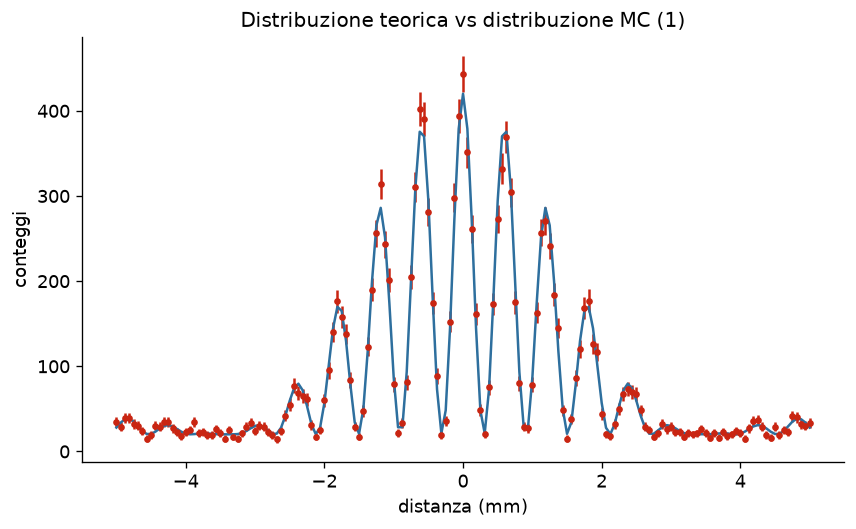

La differenza tra N_c e mu_c è: 36.41304189733182
La deviazione standard è: 87.46092294217648


In [47]:
rng = np.random.default_rng(120)


def poisson(x):
    n = rng.poisson(mu(x))
    err_n = np.where(n == 0, 1, np.sqrt(n))

    return n, err_n


fig, ax = plt.subplots()
ax.set(
    xlabel="distanza (mm)",
    ylabel="conteggi",
    title="Distribuzione teorica vs distribuzione MC (1)",
)
n, err_n = poisson(x)
mu_values = mu(x)
ax.errorbar(x, n, err_n, color=ROSSO, fmt=".")
ax.plot(x, mu_values, color=AZZURRO)
plt.show()

N_c = np.sum(n[(x >= -1.2) & (x <= 1.2)])
mu_c = np.sum(mu_values[(x >= -1.2) & (x <= 1.2)])

print(f"La differenza tra N_c e mu_c è: {abs(N_c - mu_c)}")
print(f"La deviazione standard è: {np.sqrt(mu_c)}")

## Attività 3
L'obiettivo di questa terza sezione è quello di estendere la simulazione a 2000 acquisizioni dati.

Avremo ora una matrice $$\begin{bmatrix} 
n_{1,1} & ... & n_{1,161}\\ 
... & & ...\\
... & & ...\\
n_{2000,1} & ... & n_{2000,161}
\end{bmatrix}$$
e procederemo nel calcolare gli $$ N_{c}^{(j)} = \sum_{\lvert(x_i)\rvert < 1.2 mm} n_i^{(j)} $$ 

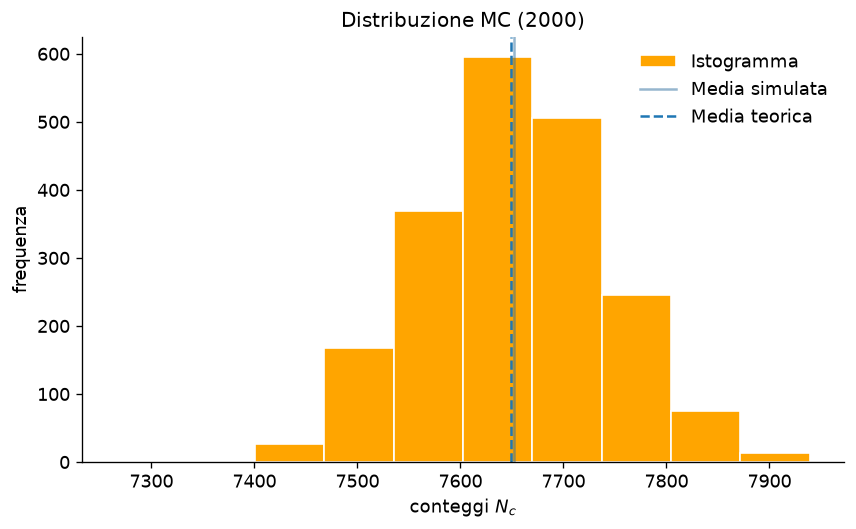

La media dei conteggi N_c è: 7652.0095
La deviazione standard simulata(1 dof) è: 88.27707420766353
La deviazione standard della media simulata è: 1.9739353878312904
L'errore relativo tra media simulata e mu_c è: 0.00033943233140202846
La deviazione standard teorica è: 87.46092294217648


In [49]:
M = 2000
samples = np.array([poisson(x) for _ in range(M)])
n = samples[:, 0]
err_n = samples[:, 1]

N_c = np.sum(n[:, (x >= -1.2) & (x <= 1.2)], axis=1)

fig, ax = plt.subplots()
ax.set(
    xlabel="conteggi $N_c$",
    ylabel="frequenza",
    title="Distribuzione MC (2000)",
)
ax.hist(N_c, color=ARANCIONE, edgecolor="white", label="Istogramma")
ax.axvline(np.mean(N_c), alpha=0.5, color=AZZURRO, label="Media simulata")
ax.axvline(np.mean(mu_c), ls="--", label="Media teorica")
ax.legend()
plt.show()

print(f"La media dei conteggi N_c è: {np.mean(N_c)}")
print(f"La deviazione standard simulata(1 dof) è: {np.std(N_c, ddof=1)}")
print(
    f"La deviazione standard della media simulata è: {np.std(N_c, ddof=1) / np.sqrt(M)}"
)
print(f"L'errore relativo tra media simulata e mu_c è: {(np.mean(N_c) - mu_c) / mu_c}")
print(f"La deviazione standard teorica è: {np.sqrt(mu_c)}")